## **CA2 Part A:**
### **Name: Cayden Sim**
### **Student ID: P2510893**
### **Class: DAAA/FT/1B/01**

---

## **Background Overview:**
- Information of 200 customers were collected and they include:
    - Gender
    - Age
    - Income
    - How much they spend
- The purpose of this study is to apply unsupervised machine learning techniques to segment customers into meaningful groups. 
    - By identifying distinct customer clusters, organisations can better understand customer behaviour and tailor strategies to meet the needs of different customer segments more effectively.

## **Planned Workflow:**
-  ### Oveerall Workflow includes:
    - Data Exploration (EDA)
        - Understand data distribution, patterns and relationships
        - Identify potential outliers/anomalies
    - Preprocessing
        - Handle any missing values
        - Feature Engineering
    - Model Building and Implementation
        - Apply different clustering models to group customers.
    - Evaluation
        - Determine most optimal number of clusters for each model.
        - Analyse cluster quality with the appropriate metrics (Graphs, visuals, etc.).
    - Model Improvement
        - Compare results across multiple clustering model
        - Determine most suitable model that achieves the best result
        - Fine-tune selected model


- ### **Libraries Used:**
    - **Data Manipulation & Numerical Operation**
        - pandas
        - numpy
    - **Machine Learning:**
        - scikit-learn
    - **Data Visualization**
        - matplotlib
        - Seaborn


## **Ultimate End Goal:**
The ultimate goal of this project is to perform customer segmentation using unsupervised learning techniques. By clustering customers based on demographic and spending behaviour, the study aims to:

- Identify distinct customer groups

- Analyse the characteristics of each cluster

- Determine which customer segment requires the most attention from a business perspective

These insights can help organisations make more data-driven decisions in marketing, customer engagement, and resource allocation.

---

## **Step 1:** Importing Necessary Libraries and Modules

- Import the required libraries as well as modules for this assignment

In [78]:
# Importing libraries and modules
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score

- Libraries added include:
    - pandas
    - numpy
    - matplotlib
    - seaborn
- **pandas** and **numpy** are used for data handling and analysis.
- **matplotlib** and **seaborn** are used to display visuals and graphs.

--- 
## **Step 2:** Importing Dataset by Loading its CSV File

- Import downloaded dataset from the file explorer.

In [79]:
# Loading dataset's csv file with .read_csv()
customer_df = pd.read_csv("C:/Users/nedya/OneDrive/Desktop/AIML/CA2/CA2 Datasets/CA2-Customer-Data.csv")

- Customer Data dataset is imported via pandas' **`.read_csv()`** method.
- Dataset is stored into a variable **`'customer_df'`**.

--- 
## **Step 3:** Exploratory Data Analysis **(EDA)**

- ### **Planned Overview**: 
    - Showcase dataset's information.

    - Check for missing data in columns. 

    - Identifying major outliers that can affect the output of the machine.

    - Visualize data spread with graphs.

    - Identifying any relationships between columns via pairplot/correlation heatmap

    - **Numerical Columns**: Age, Income (k$), How Much They Spend

    - **Categorical Columns**: Gender, Customer ID

In [80]:
print("Here is a quick look at the DataFrame:")
customer_df

Here is a quick look at the DataFrame:


,CustomerID,Gender,Age,Income (k$),How Much They Spend
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


- Here is how the original DataFrame of customer data looks like.

In [81]:
print("Here is the shape of the DataFrame: ", customer_df.shape)
customer_df.info()

Here is the shape of the DataFrame:  (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   CustomerID           200 non-null    int64 
 1   Gender               200 non-null    object
 2   Age                  200 non-null    int64 
 3   Income (k$)          200 non-null    int64 
 4   How Much They Spend  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


- Using the **`.shape`** attribute and printing it shows that the customer dataset has **200 rows** and **5 columns**.
- Using the **`.info()`** method on the DataFrame prints its information.
    - From the output, it is shown that all rows are **`non-null`**, indicating that there are no empty data cells.
    - **`dtype`** shows the types of data in each column.

In [82]:
print("DataFrame Description:")
customer_df.describe()

DataFrame Description:


,CustomerID,Age,Income (k$),How Much They Spend
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


- The **`describe()`** summary provides an overview of key statistical properties such as the mean, standard deviation, and minimum/maximum values for each numerical feature. 

In [83]:
customer_df.isnull().sum()

CustomerID             0
Gender                 0
Age                    0
Income (k$)            0
How Much They Spend    0
dtype: int64

- Using the pandas' **'.isnull()'** method together with the **'.sum()'** method, it computes the total number of empty values within each column.
- The output above shows that all columns **'.isnull().sum()'** equate to **0**, indicating that there are no missing values in each column.

---
## **Step 3.5 - Continutinuation of EDA:** Plotting Visuals

- Some visuals will be plotted for better visualization and analysis of the original features.
- These visuals represents the relationship of each feature with another.

*Before adding new features and PCA

## **Visual Representation 1: Boxplot**

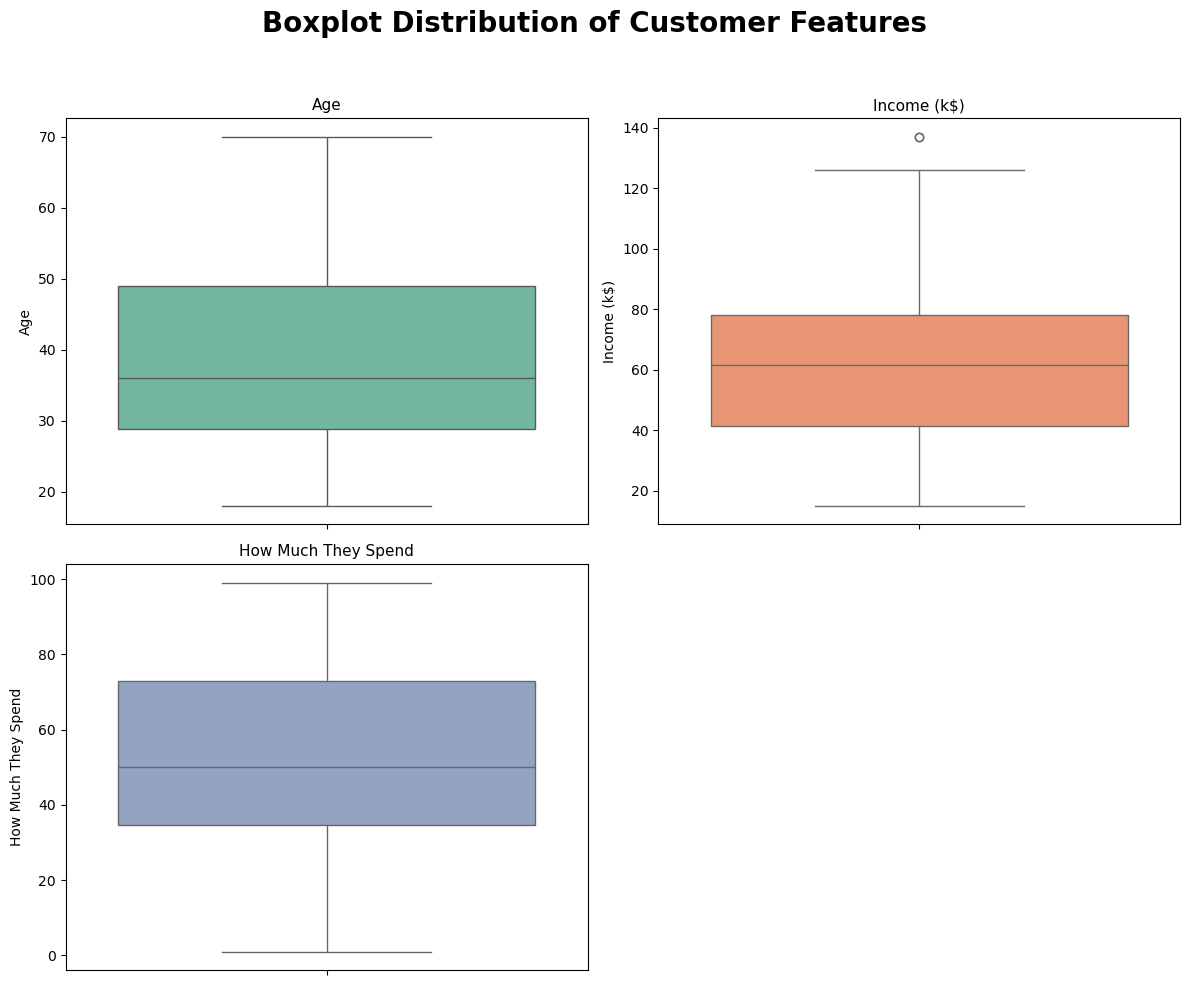

,mean,median,std
Age,38.85,36.0,13.97
Income (k$),60.56,61.5,26.26
How Much They Spend,50.20,50.0,25.82


In [84]:
# Make a list called featured_cols and store variables that will be featured in the boxplot
featured_cols = ['Age', 'Income (k$)', 'How Much They Spend']
palette = sns.color_palette("Set2", n_colors=3)

plt.figure(figsize=(12, 10))
plt.suptitle('Boxplot Distribution of Customer Features', fontsize=20, fontweight='bold') 
for i, feature in enumerate(featured_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(
        y=customer_df[feature],
        color=palette[i-1]
    )
    plt.title(feature, fontsize=11)

    # Y-axis shows the actual values of each feature
    plt.ylabel(feature)

# Adjust layout so title and plots don’t overlap
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# Summary statistics for quick numeric insight
summary_stats = customer_df[featured_cols].agg(['mean', 'median', 'std']).T

# Rounded for cleaner presentation
display(summary_stats.round(2))


# # Features you want to compare
# feature_cols = ['Age', 'Income (k$)', 'How Much They Spend']

# # Mean table by Gender (expects Gender values like 'Male'/'Female')
# feature_means = customer_df.groupby('Gender')[feature_cols].mean().T

# # Ensure consistent column order if both exist
# feature_means = feature_means[['Female', 'Male']] if set(['Female','Male']).issubset(feature_means.columns) else feature_means

# # Difference: Male - Female (positive means higher for Male)
# if set(['Female','Male']).issubset(feature_means.columns):
#     feature_means['Difference'] = feature_means['Male'] - feature_means['Female']
# else:
#     # fallback if Gender is encoded as 0/1 or other labels
#     cols = list(feature_means.columns)
#     feature_means['Difference'] = feature_means[cols[1]] - feature_means[cols[0]]

# display(feature_means.sort_values('Difference', ascending=False).round(3))



- The boxplot is used to visualise the distribution of each numerical feature in the DataFrame that includes: Age, Income (k$), and How Much They Spend.

### **Key Insights of the Boxplot:**
- **Age Distribution:** 
    - Median customer age is around the mid-30s (35-36), suggesting that most customers fall within the young to middle-aged adult group.
    - Interquartile Range (IQR) is moderately wide, suggesting a diverse range and moderate spread of the ages rather than a single dominant age group.
    - There are no extreme outliers
- **Income Distribution:**
    - Income shows a wider spread than age in terms of the IQR, indicating a significant variation in customer earnings.
    - There is a single, high-income outlier that may suggest that a small group of customers earn more than the average income the majority of the customers make.
    - The median income lies closer to the lower tail/whisker, implying that more customers are mid-income instead of high-income, with a lower number of them being high-income.
- **Spending Behaviour Distribution (How Much They Spend):**
    - Spending has a very high range, showing strong variability in purchasing behaviour
    - Median spending is around the middle range, hwoever the long whiskers/tails at both ends also suggests that there high-spending and low-spending customers.

Overall, income and spending exhibit significantly higher variability/spread than age. This shows that customers' income as well as their spending behaviour are likely to play a more significant/domninant role in defining more impactful and meaningful segments or groups.


## **Visual Representation 2: Heatmap**


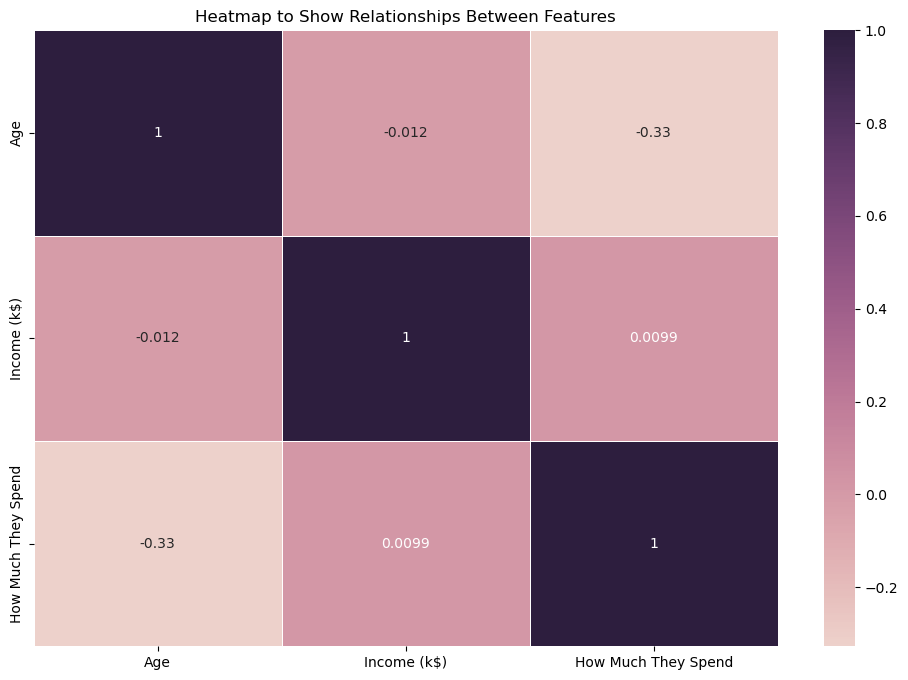

In [85]:
heatmap_cols = ['Age', 'Income (k$)', 'How Much They Spend']

# .corr() computes how strongly each number-based feature relates to another
# `numeric_only=True` ensures text columns aren't included to avoid errors
corr_matrix = customer_df[heatmap_cols].corr(numeric_only=True)

plt.figure(figsize=(12, 8))

# `annot=True` → prints correlation values inside each cell
# The heatmap helps us quickly see strong (+1 or near) or weak (0 or near) relationships
sns.heatmap(corr_matrix, annot=True, cmap=sns.cubehelix_palette(as_cmap=True), linewidths=0.5)

# Title for heatmap
plt.title('Heatmap to Show Relationships Between Features')

# Display heatmap
plt.show()

- The heatmap is used to visualize the correlation between each feature.

### **Key Insights of the Heatmap:**
- **Relationship between Age and Income:**
    - Correlation between age and income is near-zero but negative (-0.012), indicating a very weak negative to almost no linear relationship between the two features. (Both are independent information)
    - Suggests that income is distributed relatively evenly across the different age ranges in the dataset. 
- **Relationship between Income and Spending:**
    - Correlation between income and spending is also near-zero but positive (0.0099), indicating a very small, almost non-existent positive linear relationship. However, due to its small value, the correlation between the two features can be taken as almost no linear relationship.
    - Shows that customers with a higher income may not necessarily spend more.
    - Highlights that customers that have similar incomes have different spending habits, some might spend more than others, but it still does not mean that higher income results in higher spending.
- **Relationship between Age and Spending:**
    - Correlation between age and spending is a low to moderate negative correlation (-0.33).
        - Suggests that younger customers tend to spend more while older ones spend lesser. (Spending decreases as Age increase)
    - Not a strong correlation but the strongest and most noticeable relationship as compared to the others.

Overall, no relationship between a pair of features exhibits a strong correlation be it positive or negative, indicating low linear relationship (multicollinearity) in the dataset. This highlights that the change in one feature does not affect the change in other features.
        


## **Visual Representation 3:** Pairplot for Multivariate Analysis
- Similar to the heatmap, the pairplot compares relationships between features, but instead of displaying correlation values, it visualises these relationships using scatter plots.

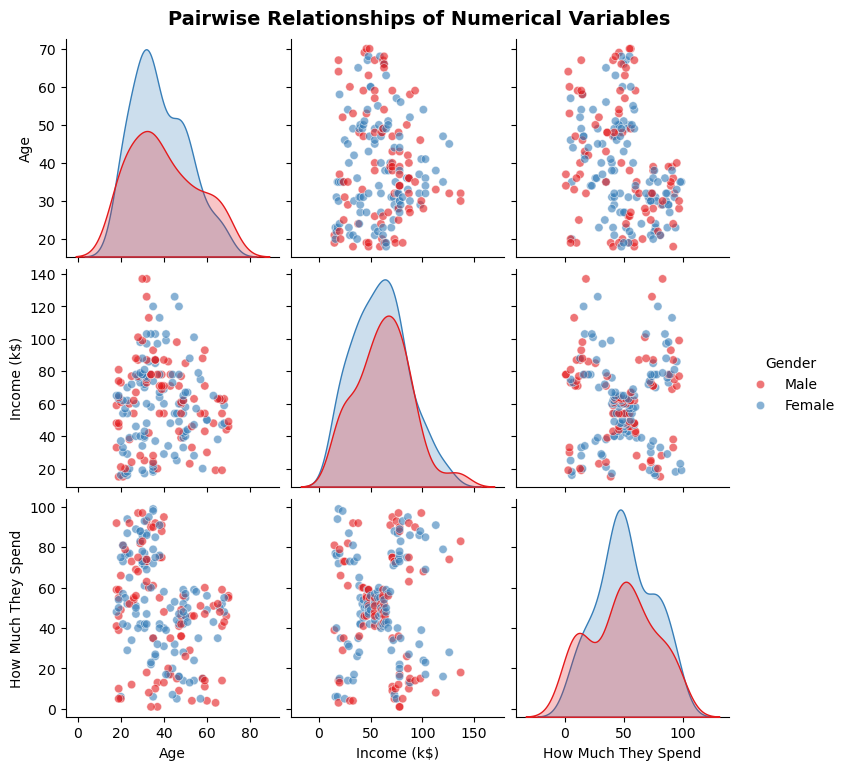

In [86]:
# include relevant numerical columns for pairwise relationships
numerical_cols = ['Age', 'Income (k$)', 'How Much They Spend']

# sns.set(style="whitegrid", font_scale=1.1) Different styling jsut in case


pairplot_cols = ['Age', 'Income (k$)', 'How Much They Spend', 'Gender']
sns.pairplot(customer_df[pairplot_cols], diag_kind='kde', hue='Gender', palette='Set1', plot_kws={'alpha': 0.6}) # still thinking whether to use corner=True

plt.suptitle('Pairwise Relationships of Numerical Variables', y=1.02, fontsize=14, fontweight='bold')
plt.grid(True)
plt.show()

- The pairplot above visualizes the relationships between the features via the scatter plots shown on the pairplot.
- The Kernal Density Estimaton (KDE) plots on the diagonal represents the distribution of each feature.

### **Key Insights of the Pairplot:**
- **Age vs Income:** 
    - The scatter plot shows a widely dispersed pattern with no clear upward or downward trend.
    - Shows that customers across different age groups have differerent income levels, doesn't show that as age increases, income increases/decreases. 
    - Scatter plot visually confirms the near-zero correlation observed from the heatmap.
- **Income vs Spending:** 
    - The scatter plot indicates no strong linear relationship between the two.
    - Customers that may have similar incomes have varying and inconsistent spending habits.
    - Suggests that income alone is not a reliable factor of spending behaviour.
        - Visually confirms the near-zero correlation observed from the heatmap.
- **Age vs Spending:**
    - A weak downward trend can be observed since the scatter plots show that younger customers tend to spend more than older ones.
    - Spending still remains widely spread out, indicating significant variability within age groups.
    - Aligns with weak-moderate negative correlation observed from the heat map

- **Distribution of Individual Features (KDE):**
    - KDE plots show that:
        - **Age** is slightly right-skewed or positively-skewed, with its peak being towards the younger to middle-aged customers.
        - **Income** is also right-skewed with a broader distribution due to the longer right tail. Suggesting that there is a presence of high-income customers.
        - **Spending** is more normally distributed than the other 2 features as it does not have a very clear left or right skew as compared to the 2 features. This shows the diverse spending behaviour across customers, where different customers spend different amounts, reardless of their income or age.

Overall, the pairplot reveals weak linear relationships and overlapping patterns among features, indicating that meaningful customer segmentation will require multi-dimensional clustering rather than single-feature separation.

--- 
## **Step 4:** Preprocessing + Feature Engineering

### **Preprocessing:**
- Convert any text-based columns into numeric data.
- Drop irrelevant columns

In [87]:
# Label Encoder converts text-based data into numeric format, in this case, convert Gender to represent 0 and 1 instead of 'Male' and 'Female'
le = LabelEncoder()
customer_df['Gender'] = le.fit_transform(customer_df['Gender'])

# drop 'Customer ID' column as it is irrelevant
customer_df = customer_df.drop(columns=['CustomerID'])

print("New shape of DataFrame: ", customer_df.shape)
customer_df

New shape of DataFrame:  (200, 4)


,Gender,Age,Income (k$),How Much They Spend
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40
...,...,...,...,...
195,0,35,120,79
196,0,45,126,28
197,1,32,126,74
198,1,32,137,18


- From the output, the new shape is now **(200, 4)** instead of the original **(200, 5)**, showing that the DataFrame now has 200 rows but only 4 columns, meaning that the **'CustomerID'** column has been **dropped**.

- **'CustomerID'** column was dropped to its irrelevance as it is only an identifier, it does not describe customer characteristics and has no real meaning.
    - Including it may affect the results of the model's prediction as it may cluster based on the CustomerID instead of the other meaningful features.
- Additionally, the **'Gender'** column now contains only 0s and 1s, where **'0s'** represents **'Female'**, while **'1s'** represent **'Male'**.

### **Feature Engineering:**
- Feature engineering includes the creation of new derived features, dimensionality reduction through Principal Component Analysis (PCA), and anomaly detection to identify unusual or extreme observations.

- What is being covered in Feature Engineering:
    - Add new features
    - Reduce dimensions via Principal Component Analysis (PCA)
    - Anomaly detection

- More graphs will be plotted to visualise any new relationships formed by the new features.
- A before VS after graph before PCA as well as Anomaly Detection, just to see how does the result differ.

### **Feature Engineering 1:** Adding New Features

In [88]:
customer_df['Spending-Income_Ratio'] = customer_df['How Much They Spend'] / customer_df['Income (k$)'] # KIV whether to round to 2dp

# Research More on this part
customer_df['Income_Category'] = pd.qcut(
    customer_df['Income (k$)'],
    q=3,
    labels=['Low Income', 'Medium Income', 'High Income']
)

customer_df['Spending_Category'] = pd.qcut(
    customer_df['How Much They Spend'],
    q=3,
    labels=['Low Spender', 'Medium Spender', 'High Spender']
)

customer_df

,Gender,Age,Income (k$),How Much They Spend,Spending-Income_Ratio,Income_Category,Spending_Category
0,1,19,15,39,2.600000,Low Income,Low Spender
1,1,21,15,81,5.400000,Low Income,High Spender
2,0,20,16,6,0.375000,Low Income,Low Spender
3,0,23,16,77,4.812500,Low Income,High Spender
4,0,31,17,40,2.352941,Low Income,Low Spender
...,...,...,...,...,...,...,...
195,0,35,120,79,0.658333,High Income,High Spender
196,0,45,126,28,0.222222,High Income,Low Spender
197,1,32,126,74,0.587302,High Income,High Spender
198,1,32,137,18,0.131387,High Income,Low Spender


- New Columns added:
    - **'Spending-Income_Ratio':**
        - Takes the ratio between a customer's spending and their income.
        - If income is low but ratio is high, it suggests that the customer is a high spender.
    - **'Income Category':**
        - Split income into 3 properties: 'Low income', 'Medium Income', 'High Income'.
    - **'Spending Category':**
        - Split spending into 3 properties: 'Low Spender', 'Medium Spender', 'High Spender'


- **'pd.qcut()'** method is applied to the **'Income Category'** and **'Spending Category'** so that its data labels are strings of income status as well as Spending status for analysis and comparison.
- These categorical features will be useed for cluster interpretation and comparison after fitting the cluster models.

### **Feature Engineering 2:** Data Scaling

In [89]:

features_to_scale = ['Age', 'Income (k$)', 'How Much They Spend', 'Spending-Income_Ratio']
scaler = StandardScaler()
scaled_data = scaler.fit_transform(customer_df[features_to_scale])
scaled_customer_df = pd.DataFrame(scaled_data, columns=features_to_scale, index=customer_df.index)

scaled_customer_df

,Age,Income (k$),How Much They Spend,Spending-Income_Ratio
0,-1.424569,-1.738999,-0.434801,1.577244
1,-1.281035,-1.738999,1.195704,4.460960
2,-1.352802,-1.700830,-1.715913,-0.714279
3,-1.137502,-1.700830,1.040418,3.855894
4,-0.563369,-1.662660,-0.395980,1.322799
...,...,...,...,...
195,-0.276302,2.268791,1.118061,-0.422475
196,0.441365,2.497807,-0.861839,-0.871625
197,-0.491602,2.497807,0.923953,-0.495630
198,-0.491602,2.917671,-1.250054,-0.965176


- **`'features_to_scale'`** is a list that contains all the numerical features selected for scaling.
- These features are to be used for subsequent steps, including PCA, anomaly detection and clustering model fitting.
- After scaling, the list is converted back into a pandas DataFrame for easier handling and interpretation.
- Printing the DataFrame shows that there are only 4 columns, which are the numerical columns.

### **Feature Engineering 3:** Dimension Reducion via Principle Component Analysis **(PCA)**
- Dimension Reduction removes less-informative, noisy features.
- Implement dimensionality reducion via Principal Component Analysis (PCA).
- PCA:
    - Rotates data samples to be aligned with axes.
    - Shifts data samples so that they have a mean of 0.
    - No information is lost



#### **Feature Engineering 3.5:** Intrinsic Dimension Identification

- Before the actual PCA implementation, the number of components, n_components, must be found.
- Generally, the recommended number of components, n_components, is the intrinsic dimension of our data.
- Intrinsic Dimension can be identified by counting the PCA features that have a high variance.
- Thus, a graph will be plotted to display the PCA features' variance and from there, identify the number of features with high variance.
    - The number of identified, high-variance features will then be our intrinsic dimension.

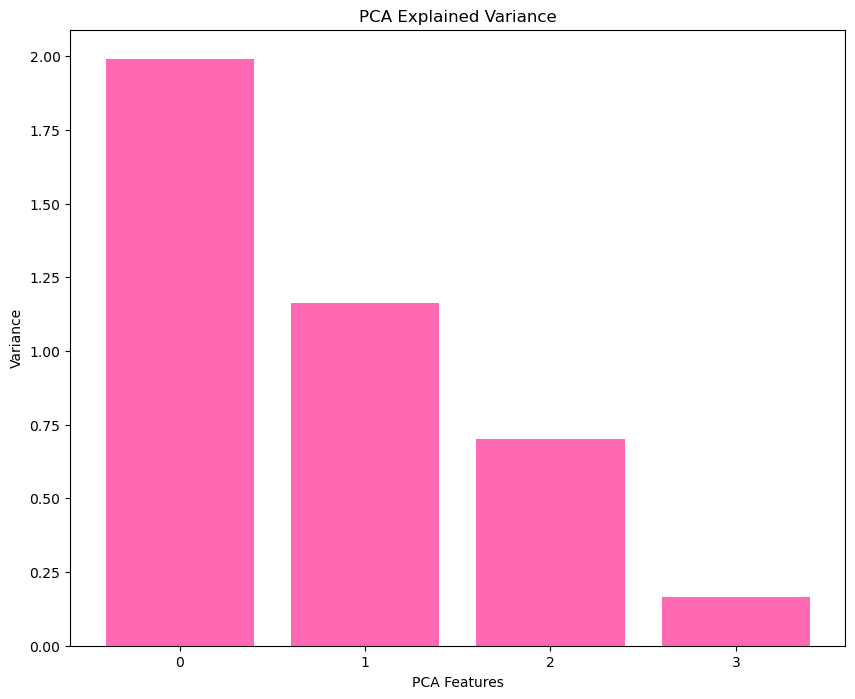

In [90]:
pca = PCA()
pca.fit(scaled_customer_df)

plt.figure(figsize=(10, 8))
features = range(pca.n_components_)
plt.bar(features, pca.explained_variance_, color='hotpink')
plt.xticks(features)
plt.ylabel('Variance')
plt.xlabel('PCA Features')
plt.title('PCA Explained Variance')
plt.show()

### **Key Insights:**
- A bar chart was plotted to determine the number of principle components to be used.
- Generally, each PCA feature has less variance than previous one.
    - The first PCA feature has the highest, while the last PCA feature has the lowest.
- Principle Component 1 (PC1) explains the largest proportion of variance, indicating that it captures the most significant underlying / important pattern/information in the customer data.
- PC2 contributes a substantial amounts of variance, but it is less than PC1.
- The sharp drop in variance explained after PC2 suggests that the data's structure can be represented with fewer dimensions without significant information loss. (Low variance -> Does not explain alot of information)
- Including the later components despite their low variance may introduce noise instead of meaningful information. 
    - Noise refers to irrelevant data that disrupts patterns in a dataset.

All in all, the number of components will be 2.

In [91]:
pca = PCA(n_components=2)
pca.fit(scaled_customer_df)
pca_data = pca.transform(scaled_customer_df)
print("Shape of PCA data:", pca_data.shape)
pca_df = pd.DataFrame(pca_data, columns=['PC1', 'PC2'], index=scaled_customer_df.index)
pca_df



Shape of PCA data: (200, 2)


,PC1,PC2
0,2.013603,-1.042412
1,4.718243,-1.008237
2,-0.213915,-1.129127
3,4.167502,-1.000753
4,1.505260,-1.357193
...,...,...
195,-0.434797,2.349612
196,-2.132281,1.459574
197,-0.587571,2.565717
198,-2.194990,2.106931


- After identifying **`'n_components'`** to be **`2`**, the pca model is once again fitted into **`'scaled_customer_df'`** and then transformed, equating the output to **`'pca_data'`**.
- Printing the shape of **`'pca_data'`** now outputs **`(200, 2)`**, showing that are only 2 features.
- Convert PCA output into a DataFrame, **`'pca_df'`**.

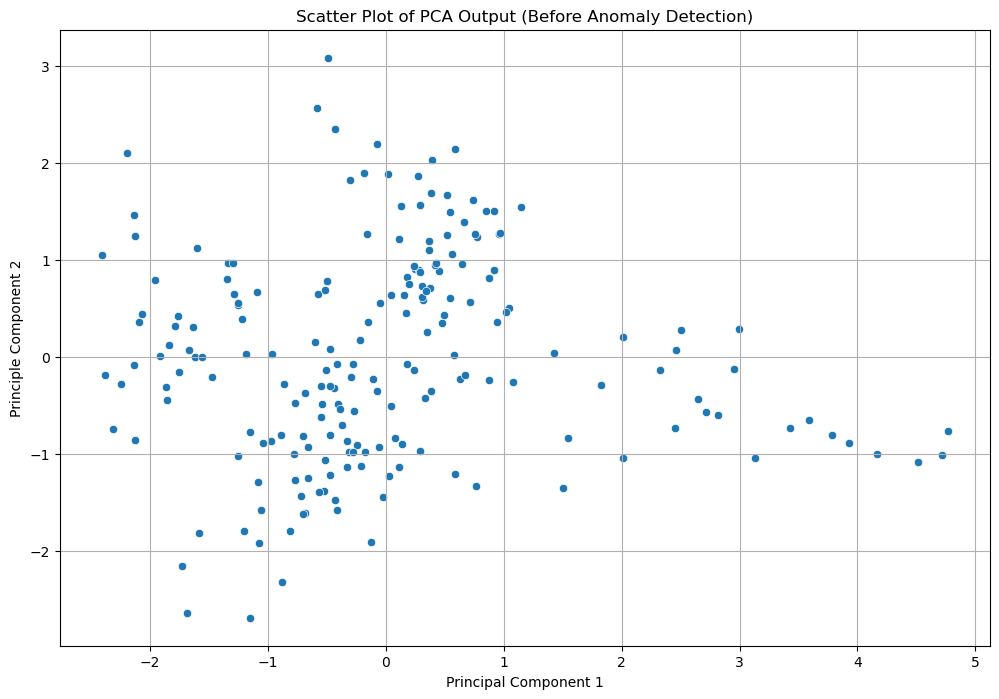

In [92]:
plt.figure(figsize=(12, 8))


sns.scatterplot(data=pca_df, x='PC1', y='PC2')
plt.xlabel('Principal Component 1')
plt.ylabel('Principle Component 2')
plt.title('Scatter Plot of PCA Output (Before Anomaly Detection)')
plt.grid(True)
plt.show()

### **Key Insights: Scatter Plot**
- Majority of the data points are concentrated near the center of the plot, more towards the left (negative) side, forming a dense central region
    - Indicate that most customers share similar behavioural patterns after dimension reduction, due to the data points not being very widely spread.
- Small number of data points that trail away form the central cluster in the positive direction (towards the right).
    - May represent customers with higher incomes or spending behaviour than the majority customers.



### **Feature Engineering 4:** Anomaly Detection
- After implementing PCA, we move on to anomaly detection.
- Anomaly Detection allows us to identify anomalies and remove them to further optimise our dataset before fitting clustering models in order to get the best results.

Visual will be plotted after anomaly detection to compare the difference in data spread in the scatter plot.

In [93]:

isoForest = IsolationForest(contamination=0.05, random_state=42) 
pca_df['Anomaly_IF'] = isoForest.fit_predict(pca_df)
pca_df[pca_df['Anomaly_IF'] == -1]

,PC1,PC2,Anomaly_IF
1,4.718243,-1.008237,-1
3,4.167502,-1.000753,-1
7,4.763813,-0.761803,-1
8,-1.683137,-2.641039,-1
10,-1.148331,-2.692083,-1
11,4.511307,-1.088849,-1
30,-1.725848,-2.163484,-1
197,-0.587571,2.565717,-1
198,-2.194990,2.106931,-1
199,-0.493421,3.085311,-1


- Using Isolation Forest's **`'.fit_predict()'`** function on the pca DataFrame to fit the Isolation Forest model and predict the anomaly.
    - Where **`1`** is classified as **`normal`**, and **`-1`** classified as the **`anomaly`**.
- Add a new column called **`'Anomaly_IF'`** to carry out the anomaly prediction.
- Printing **`'pca_df[pca_df['Anomaly_IF'] == -1]'`** shows all the rows where the value of the cell is -1, which represents the anomaly that Isolation Forest predicts.

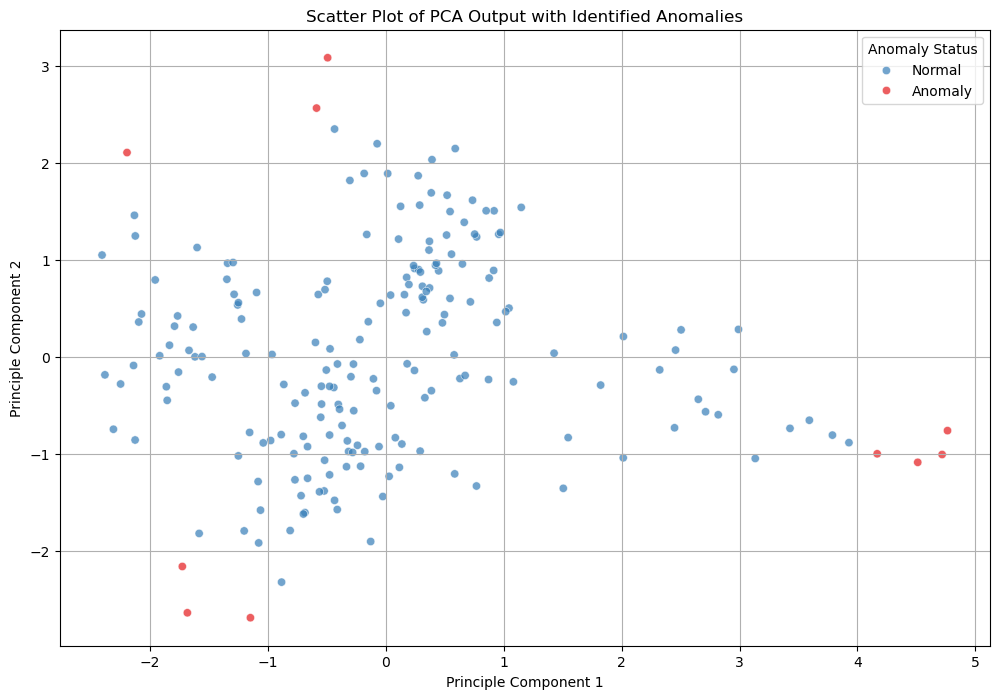

In [94]:
# plt.figure(figsize=(10, 8))

""" plt.scatter(
    pca_df.loc[pca_df['Anomaly_IF'] == 1, 'PC1'],
    pca_df.loc[pca_df['Anomaly_IF'] == 1, 'PC2'],
    label='Normal',
    alpha=0.6
)

plt.scatter(
    pca_df.loc[pca_df['Anomaly_IF'] == -1, 'PC1'],
    pca_df.loc[pca_df['Anomaly_IF'] == -1, 'PC2'],
    label='Anomaly',
    color='red'
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA + Isolation Forest Anomaly Detection')
plt.legend()
plt.grid(True)
plt.show()
 """
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Anomaly_IF',
    palette='Set1',
    alpha=0.7
)

plt.title('Scatter Plot of PCA Output with Identified Anomalies')
plt.xlabel('Principle Component 1')
plt.ylabel('Principle Component 2')
plt.legend(title='Anomaly Status', labels=['Normal', 'Anomaly'])
plt.grid(True)
plt.show()



### **Key Insights:**
- From the visual above, the anomalies are clearly highlighted in red, separating them from the majority of the data points.
- These identified anomalies share a common characteristic:
    - They are positioned far from the dense central region of the PCA space.
- These anomalies represent unusual income or spending behaviour, i.e. customers with higher income and spending.


## **Summary of Feature Engineering:**
- What was accomplished in Feature Engineering:
    - Step 1: Add new columns
    - Step 2: Scale the data (Numerical Columns)
    - Step 3: Find intrinsic dimension and incorporate it into PCA on the scaled data
    - Anomaly Detection using Isolation Forest on the PCA data

- Note: For anomaly detection, the anomalies were not removed, only labeled due to the small dataset size of 200 rows. Removing these anomalies might drastically affect our results. Hence, they were kept.

---
## **Step 5:** Cluster Model Fitting
- Cluster models from scikit-learn will be used to fit to the scaled numerical data
- Cluster models used include
    - KMeans
    - AgglomerativeClustering (Hierarchial Clustering)
    - DBSCAN

### **Cluster Model 1:** KMeans
- Before determining the n_clusters value, a graph will be plotted to visualise the inertia values and identify the recommended number of clusters from there.

### **Determining Optimal n_clusters Value:**

### **Elbow Graph:**

c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

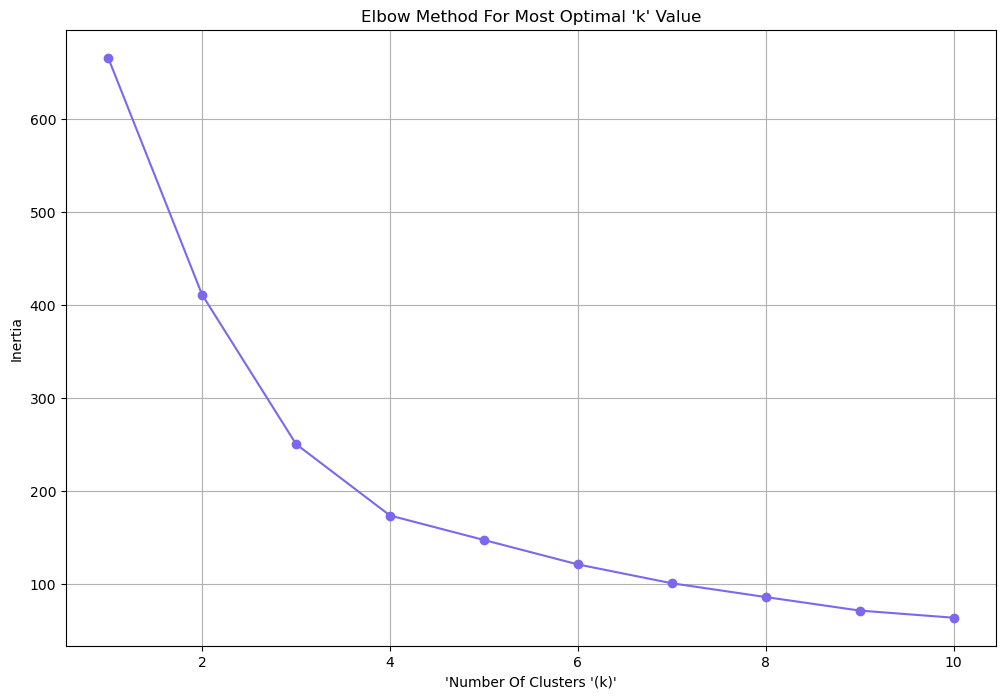

In [95]:
inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10) # n_init to ensure data is not unstable.
    kmeans.fit(pca_df)
    inertia.append(kmeans.inertia_)

""" elbow_df = pd.DataFrame({
    'Number Of Clusters': list(k_range),
    'Inertia': inertia
})

plt.figure(figsize=(10, 8))
sns.lineplot(data=elbow_df, x='Number Of Clusters', y='Inertia', markers='o')

plt.title("Elbow Graph For Most Optimal 'k' Value")
plt.xlabel("Number Of Clusters 'k")
plt.ylabel('Inertia')
plt.grid(True)
plt.show() """
plt.figure(figsize=(12, 8))
plt.plot(k_range, inertia, marker='o', color='mediumslateblue')
plt.xlabel("'Number Of Clusters '(k)'")
plt.ylabel('Inertia')
plt.title("Elbow Method For Most Optimal 'k' Value")
plt.grid(True)
plt.show()

### **Key Insights:**
- Above is a line plot to determine the most optimal value of n_clusters by identifying the elbow.
    - The elbow is a point in the graph where the inertia decreases more slowly.
- From the graph, the point at which the inertia decreases more slowly is when k = 4.

### **Silhouette Score Graph:**

c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

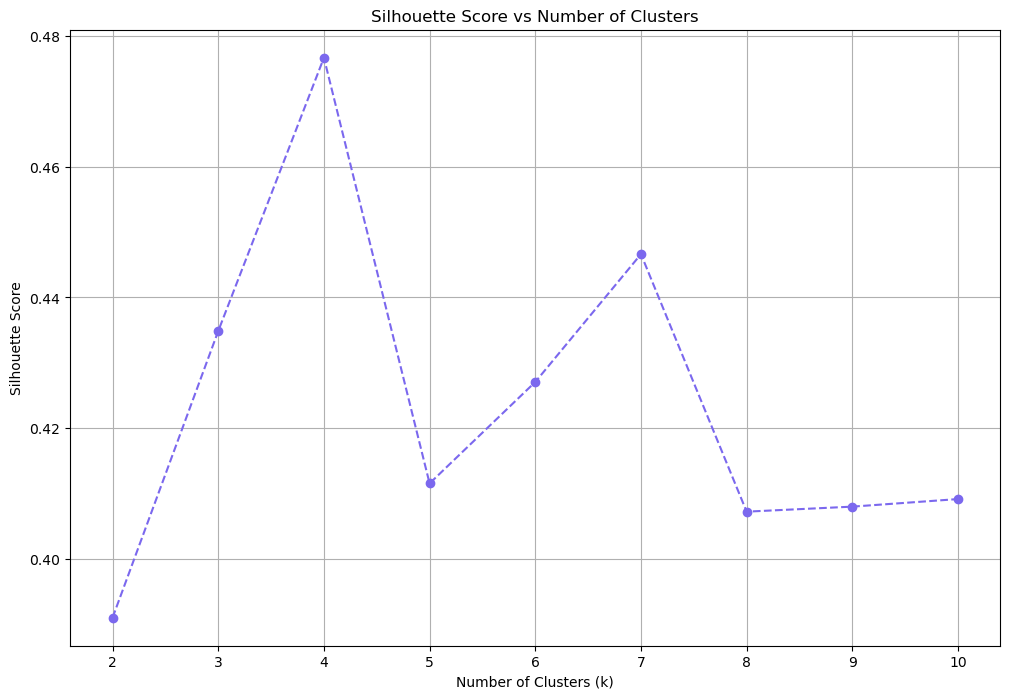

In [96]:
k_values = range(2, 11)
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(pca_df)
    silhouette_scores.append(silhouette_score(pca_df, labels))


plt.figure(figsize=(12, 8))
plt.plot(list(k_values), silhouette_scores, marker='o', linestyle='--', color='mediumslateblue')
plt.title('Silhouette Score vs Number of Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

### **Key Insights:**
- The silhouette score graph is plotted to serve as a confirmatory test. Its purpose is to double check the elbow graph's n_cluster value and confirm it.
- From the elbow graph, I selected the point at which number of clusters is 4, as that is the where the inertia decreases more slowly.
- To determine the most optimal n_clusters value from the silhouette score graph, select the highest the number of clusters that give the highest silhouette score.
- From the silhouette score graph, the number of clusters that give the highest silhouette score is 4, which perfectly matches with the elbow graph. 
- Hence, the n_clusters value will be 4.

## **Model Fitting - KMeans:**
- After determining n_clusters value to be 4, we can now continue with the model fitting process.

In [97]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(pca_df[['PC1', 'PC2']])
kmeans_labels = kmeans.fit_predict(pca_df[['PC1', 'PC2']])

c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


- Since **`'pca_df'`** includes the anomaly column, the KMeans model is fitted only into the 2 Principle Components. 
- After that use the **`'.predict()'`** function of the KMeans model and assign it to the variable **`'kmeans_labels'`**.

In [98]:
pca_df['KMeans_Cluster'] = kmeans_labels

pca_df

,PC1,PC2,Anomaly_IF,KMeans_Cluster
0,2.013603,-1.042412,1,2
1,4.718243,-1.008237,-1,2
2,-0.213915,-1.129127,1,0
3,4.167502,-1.000753,-1,2
4,1.505260,-1.357193,1,2
...,...,...,...,...
195,-0.434797,2.349612,1,1
196,-2.132281,1.459574,1,3
197,-0.587571,2.565717,-1,1
198,-2.194990,2.106931,-1,3


- Create a new column for **`'pca_df'`** called **`'KMeans_Cluster'`**.
- Creating it for **`'pca_df'`** is so that we can use it for further modelling and plotting visuals.


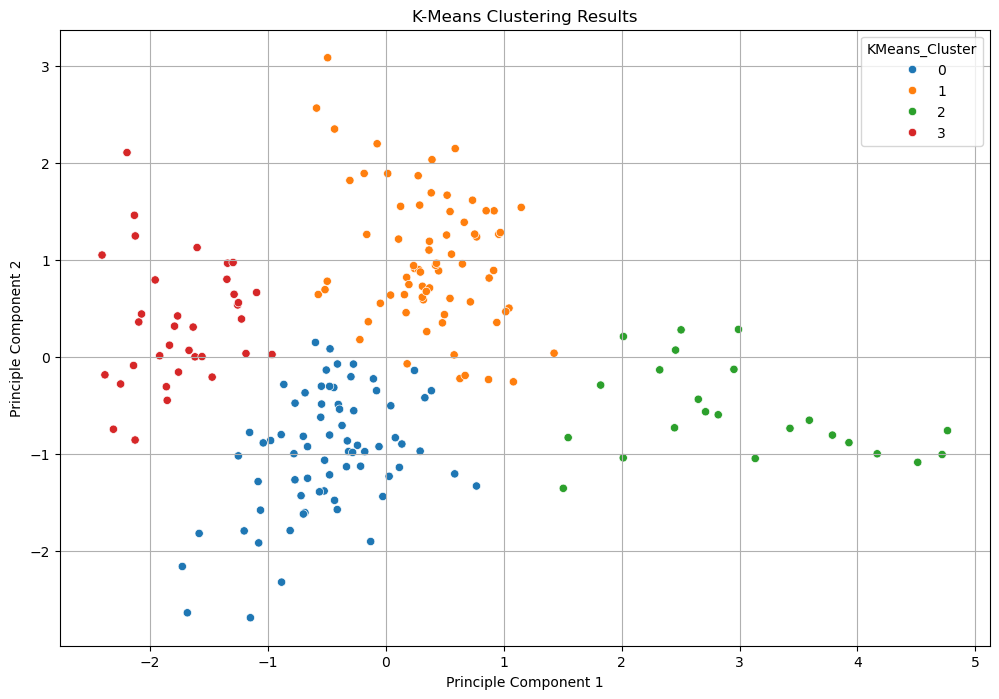

In [100]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='KMeans_Cluster',
    palette='tab10'
)

plt.title('K-Means Clustering Results')
plt.xlabel('Principle Component 1')
plt.ylabel('Principle Component 2')
plt.grid(True)
plt.show()

### **Key Insights:**
- The KMeans algorithm has segmented the customers into four distinct clusters, which are distinguished by their different color.
- Each cluster occupies a different region of the Principle Component space, indicating meaningful differences in customer behaviour.
- Minimal overlap between clusters can be observed.
    - Suggests that the n_clusters value of 4 was the appropriate choice for this dataset.

## **Model Fitting 2: AgglomerativeClustering (Hierarchial Clustering)**